In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import IsolationForest

# Đọc dữ liệu đặc trưng đã chuẩn hóa
X_train = pd.read_csv("../data/processed/X_train_scaled.csv")
X_val = pd.read_csv("../data/processed/X_val_scaled.csv")
X_test = pd.read_csv("../data/processed/X_test_scaled.csv")

# Đọc nhãn
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_val = pd.read_csv("../data/processed/y_val.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (396332, 79)
Validation: (98194, 79)
Test: (100117, 79)


In [2]:
# Chỉ lấy giao dịch bình thường trong tập Train
X_train_normal = X_train[y_train == 0]

print("Tổng số giao dịch Train:", len(X_train))
print("Số giao dịch bình thường:", len(X_train_normal))
print("Số giao dịch gian lận:", (y_train == 1).sum())

Tổng số giao dịch Train: 396332
Số giao dịch bình thường: 391292
Số giao dịch gian lận: 5040


In [3]:
# Khởi tạo mô hình
iso_forest = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Huấn luyện bằng giao dịch bình thường
iso_forest.fit(X_train_normal)

print("Huấn luyện Isolation Forest thành công!")

Huấn luyện Isolation Forest thành công!


In [4]:
joblib.dump(
    iso_forest,
    "../models/isolation_forest.pkl"
)

print("Đã lưu mô hình Isolation Forest thành công!")

Đã lưu mô hình Isolation Forest thành công!


In [5]:
# Lấy điểm bất thường trên tập Validation
val_scores = -iso_forest.decision_function(X_val)

print("5 điểm bất thường đầu tiên:")
print(val_scores[:5])

print("\nMin score:", val_scores.min())
print("Max score:", val_scores.max())

5 điểm bất thường đầu tiên:
[-0.0892245  -0.10168201 -0.12163943  0.02184334 -0.1153352 ]

Min score: -0.12577567744622786
Max score: 0.04559248027353868


In [6]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.percentile(
    val_scores,
    [90, 95, 97, 98, 99, 99.5, 99.8]
)

results = []

for threshold in thresholds:
    y_pred = (val_scores >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0),
        "Predicted_Fraud": y_pred.sum()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

   Threshold  Precision  Recall  F1-score  Predicted_Fraud
0    -0.0164     0.0285  0.2593    0.0513             9841
1    -0.0003     0.0205  0.0935    0.0336             4924
2     0.0071     0.0163  0.0444    0.0238             2952
3     0.0113     0.0193  0.0352    0.0250             1965
4     0.0185     0.0244  0.0222    0.0233              982
5     0.0228     0.0285  0.0130    0.0178              491
6     0.0283     0.0398  0.0074    0.0125              201


In [7]:
best_index = results_df["F1-score"].idxmax()

best_threshold = results_df.loc[best_index, "Threshold"]

print("Ngưỡng tốt nhất:", best_threshold)
print("Kết quả tương ứng:")
print(results_df.loc[best_index])

Ngưỡng tốt nhất: -0.01643327962226465
Kết quả tương ứng:
Threshold            -0.016433
Precision             0.028452
Recall                0.259259
F1-score              0.051277
Predicted_Fraud    9841.000000
Name: 0, dtype: float64


In [8]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Tính điểm bất thường trên Test
test_scores = -iso_forest.decision_function(X_test)

# Dùng ngưỡng đã chọn từ Validation
y_test_pred = (test_scores >= best_threshold).astype(int)


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print("PR-AUC:", average_precision_score(y_test, test_scores))


Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.90      0.94     99037
       Fraud       0.03      0.29      0.06      1080

    accuracy                           0.90    100117
   macro avg       0.51      0.60      0.50    100117
weighted avg       0.98      0.90      0.93    100117

PR-AUC: 0.036763902660779293


In [9]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Tính các chỉ số đánh giá
evaluation_results = pd.DataFrame({
    "Chỉ số đánh giá": [
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Giá trị": [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0),
        roc_auc_score(y_test, test_scores),
        average_precision_score(y_test, test_scores)
    ]
})

# Đánh số thứ tự từ 1 đến 5
evaluation_results.index = range(1, 6)
evaluation_results.index.name = "STT"

# Hiển thị bảng kết quả
print("Kết quả đánh giá mô hình Isolation Forest:")

display(
    evaluation_results.style
    .format({"Giá trị": "{:.5f}"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
)

Kết quả đánh giá mô hình Isolation Forest:


,Chỉ số đánh giá,Giá trị
STT,,
1,Precision,0.03146
2,Recall,0.29259
3,F1-Score,0.05680
4,ROC-AUC,0.85728
5,PR-AUC,0.03676


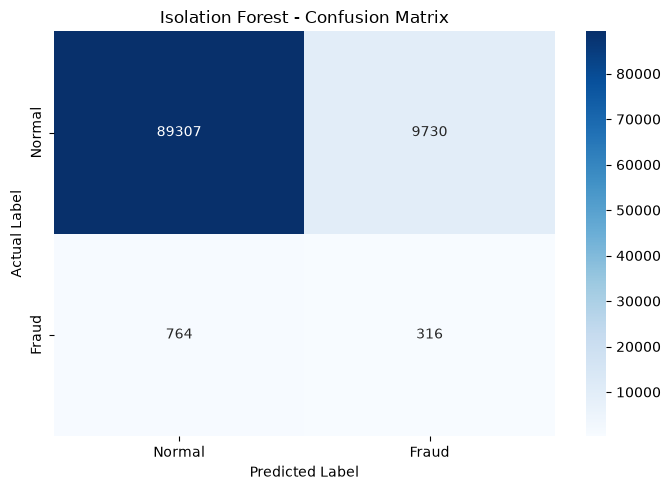

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Isolation Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

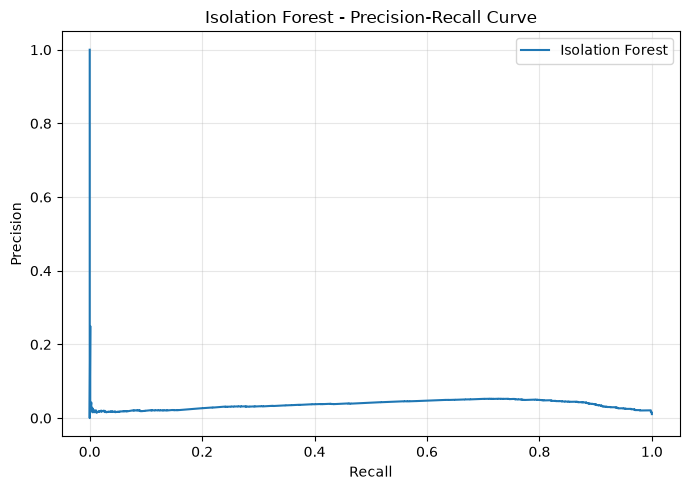

In [11]:
from sklearn.metrics import precision_recall_curve

# Tính Precision và Recall
precision, recall, _ = precision_recall_curve(
    y_test,
    test_scores
)

# Vẽ Precision-Recall Curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label="Isolation Forest"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Isolation Forest - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

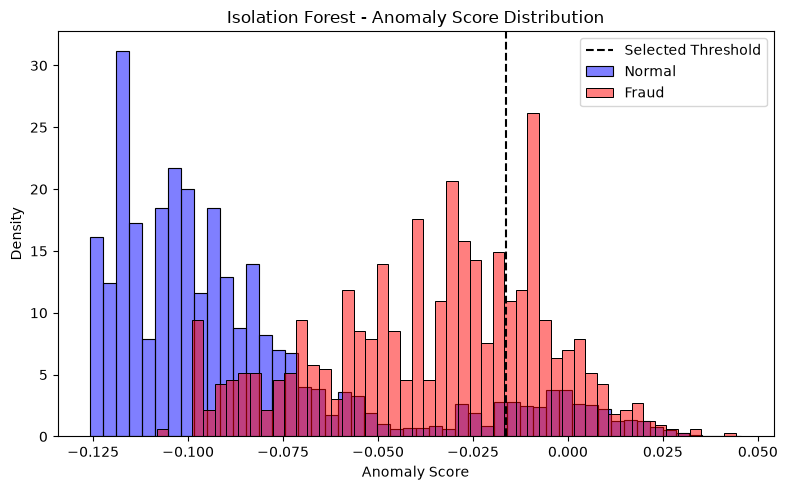

In [12]:
# Anomaly Score Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    test_scores[y_test == 0],
    bins=50,
    color="blue",
    label="Normal",
    stat="density",
    alpha=0.5
)

sns.histplot(
    test_scores[y_test == 1],
    bins=50,
    color="red",
    label="Fraud",
    stat="density",
    alpha=0.5
)

plt.axvline(
    best_threshold,
    color="black",
    linestyle="--",
    label="Selected Threshold"
)

plt.title("Isolation Forest - Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, test_scores)
print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.8573
